# ARTI403 – Image Processing
## Lab 6: Frequency Domain

**Outcome:** Write a program that implements fundamental image processing algorithms.

This notebook contains:
1. **Procedural Task #1** – Laplacian filtering in the frequency domain.
2. **Assessment Task #1** – Sobel filtering in the frequency domain.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import data, io, img_as_ubyte
from skimage.transform import resize

os.makedirs('images', exist_ok=True)

## Load the image
The Cameraman image (already grayscale) is resized to 256×256 for faster FFT computation, and saved to the `images` folder.

In [2]:
image = data.camera()
image = resize(image, (256, 256))   # values in [0, 1]
M, N = image.shape
io.imsave('images/cameraman_256.png', img_as_ubyte(image))
print('Image shape:', image.shape)

Image shape: (256, 256)


## Procedural Task #1: Laplacian Filtering in the Frequency Domain
The Laplacian in the frequency domain is **H(u,v) = −4π²(u² + v²)**.
We multiply the image spectrum F(u,v) by H(u,v) and take the inverse FFT.

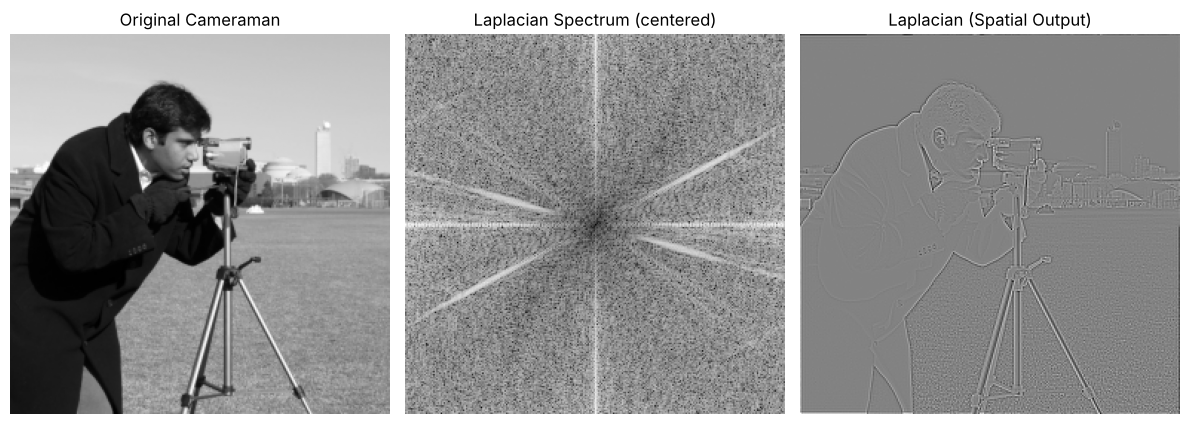

In [3]:
# Generate frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# 2D FFT, filter, inverse FFT
F = np.fft.fft2(image)
F_lap = F * laplacian_filter
laplacian_image = np.fft.ifft2(F_lap).real

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fftshift(F_lap))), cmap='gray')
plt.title('Laplacian Spectrum (centered)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.savefig('images/task1_laplacian.png', dpi=150, bbox_inches='tight')
plt.show()

## Assessment Task #1: Sobel Filtering in the Frequency Domain
By the convolution theorem, convolving an image with a kernel in the spatial domain equals multiplying their Fourier transforms:

**f(x,y) ∗ h(x,y)  ⟺  F(u,v) · H(u,v)**

To get H(u,v), each 3×3 Sobel kernel is zero-padded to the image size, centered, and then `ifftshift`-ed so the kernel center sits at the origin (0,0) before taking the FFT. This avoids a spatial shift in the output.

In [4]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))   # Shift before FFT to place (0,0) at top-left

In [5]:
# FFT of the image
F = fft2(image)

# FFT of centered Sobel filters
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
F_sx = F * H_x
F_sy = F * H_y

# Inverse FFT back to the spatial domain
sobel_x_img = np.real(ifft2(F_sx))
sobel_y_img = np.real(ifft2(F_sy))

# Gradient magnitude
sobel_mag = np.sqrt(sobel_x_img**2 + sobel_y_img**2)

### Filter frequency responses

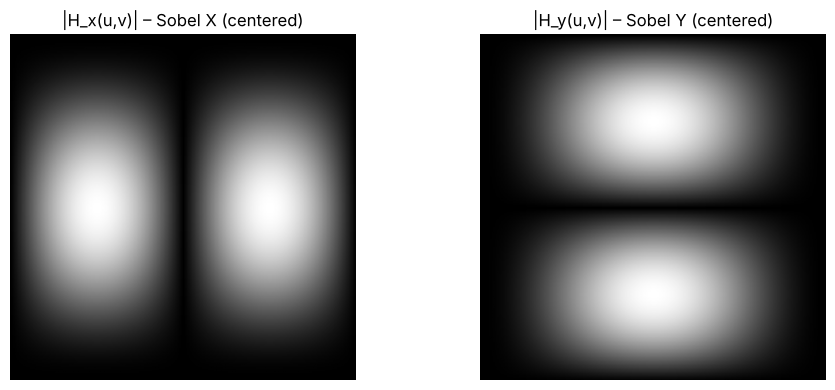

In [6]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(fftshift(np.abs(H_x)), cmap='gray')
plt.title('|H_x(u,v)| – Sobel X (centered)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(fftshift(np.abs(H_y)), cmap='gray')
plt.title('|H_y(u,v)| – Sobel Y (centered)')
plt.axis('off')

plt.tight_layout()
plt.savefig('images/assessment_sobel_filters_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

### Results

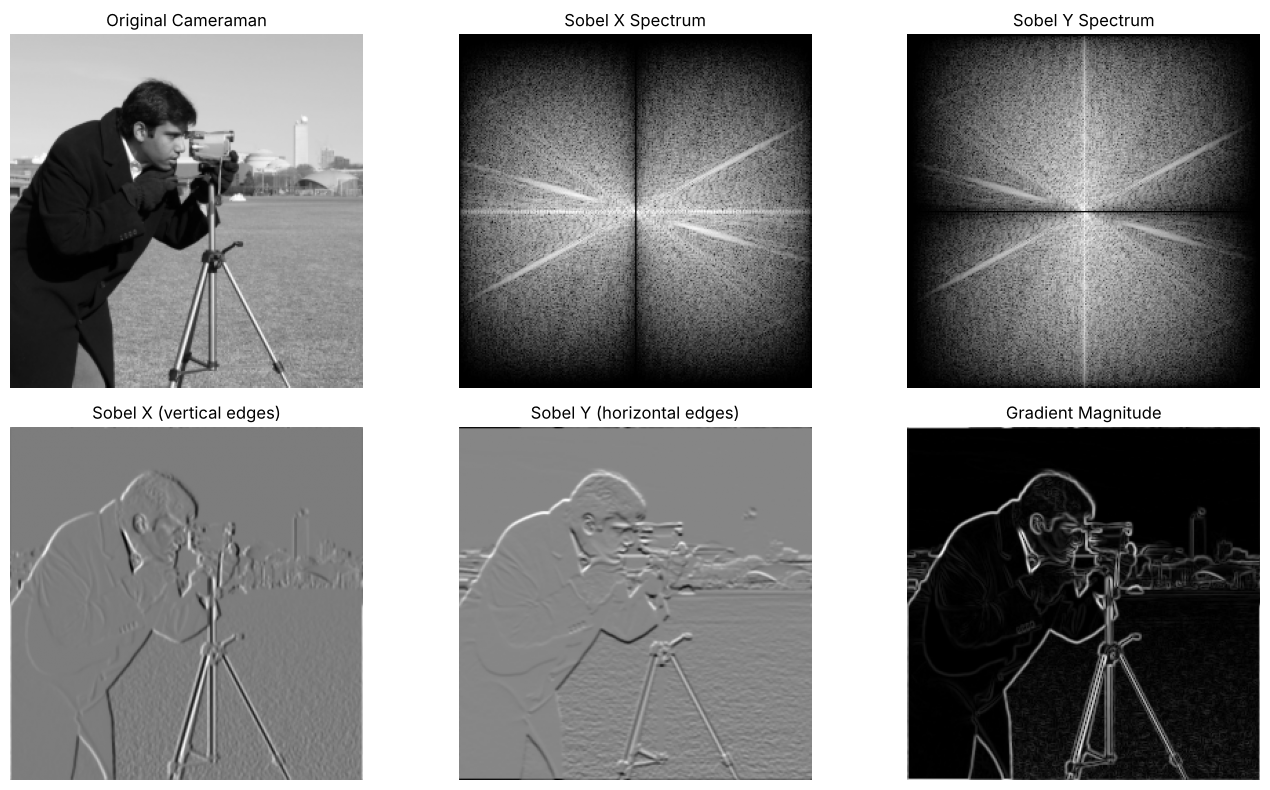

In [7]:
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(fftshift(F_sx))), cmap='gray')
plt.title('Sobel X Spectrum')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(np.log(1 + np.abs(fftshift(F_sy))), cmap='gray')
plt.title('Sobel Y Spectrum')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(sobel_x_img, cmap='gray')
plt.title('Sobel X (vertical edges)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(sobel_y_img, cmap='gray')
plt.title('Sobel Y (horizontal edges)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(sobel_mag, cmap='gray')
plt.title('Gradient Magnitude')
plt.axis('off')

plt.tight_layout()
plt.savefig('images/assessment_sobel_results.png', dpi=150, bbox_inches='tight')
plt.show()

### Verification against spatial-domain convolution
Frequency-domain multiplication corresponds to **circular** convolution, so we compare with `scipy.ndimage.convolve` using `mode='wrap'`. The results should match up to floating-point error.

In [8]:
from scipy.ndimage import convolve

spatial_x = convolve(image, sobel_x, mode='wrap')
spatial_y = convolve(image, sobel_y, mode='wrap')

print('Max |difference| Sobel X:', np.max(np.abs(spatial_x - sobel_x_img)))
print('Max |difference| Sobel Y:', np.max(np.abs(spatial_y - sobel_y_img)))

Max |difference| Sobel X: 1.4883927423881005e-15
Max |difference| Sobel Y: 2.8380076066980564e-15


## Conclusion
- The **Laplacian** filter is a high-pass filter (H ∝ u² + v²): it suppresses low frequencies and keeps edges in all directions.
- The **Sobel** filters were applied in the frequency domain by padding each kernel to the image size, centering it with `ifftshift`, taking its FFT, and multiplying it with the image spectrum.
  - |H_x| is strong along the horizontal frequency axis, so Sobel X picks up **vertical edges** (e.g., the tripod legs and the man's coat).
  - |H_y| is strong along the vertical frequency axis, so Sobel Y picks up **horizontal edges** (e.g., the horizon and the shoulders).
  - Combining both into the gradient magnitude gives a full edge map.
- The frequency-domain result matches circular spatial convolution to floating-point precision, which confirms the convolution theorem.